# 04 — Model Evaluation & Validation

## Objective
Evaluate discrimination, classification behaviour, probability quality, and risk ranking using a holdout dataset.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Load holdout data and trained models

In [2]:
import joblib
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from src.evaluation import evaluate_probabilities, decile_table
processed = PROJECT_ROOT / "data" / "processed"
X_test = pd.read_csv(processed / "X_test.csv")
y_test = pd.read_csv(processed / "y_test.csv").squeeze()
model_paths = {
    "Logistic Regression": PROJECT_ROOT / "models" / "logistic_regression.joblib",
    "Random Forest": PROJECT_ROOT / "models" / "random_forest.joblib",
    "XGBoost": PROJECT_ROOT / "models" / "xgboost.joblib"
}
models = {name: joblib.load(path) for name, path in model_paths.items() if path.exists()}
print("Models loaded:", list(models))

Models loaded: ['Logistic Regression', 'Random Forest', 'XGBoost']


## 2. Calculate ROC-AUC, Gini, KS, Brier score and threshold metrics

In [3]:
evaluation_rows = []
probabilities_by_model = {}
for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]
    probabilities_by_model[name] = probs
    row = evaluate_probabilities(y_test, probs, threshold=0.50)
    row["Model"] = name
    evaluation_rows.append(row)
evaluation = pd.DataFrame(evaluation_rows).set_index("Model")
display(evaluation.round(4))
evaluation.to_csv(PROJECT_ROOT / "reports" / "model_evaluation_metrics.csv")

,ROC_AUC,GINI,KS,Brier_Score,Average_Precision,Threshold,TN,FP,FN,TP,Sensitivity,Specificity
Model,,,,,,,,,,,,
Logistic Regression,0.7487,0.4974,0.3854,0.1922,0.5099,0.5,3645,1028,528,799,0.6021,0.7800
Random Forest,0.7744,0.5487,0.4201,0.1482,0.5545,0.5,4123,550,647,680,0.5124,0.8823
XGBoost,0.7812,0.5624,0.4370,0.1343,0.5636,0.5,4432,241,847,480,0.3617,0.9484


## 3. ROC curves

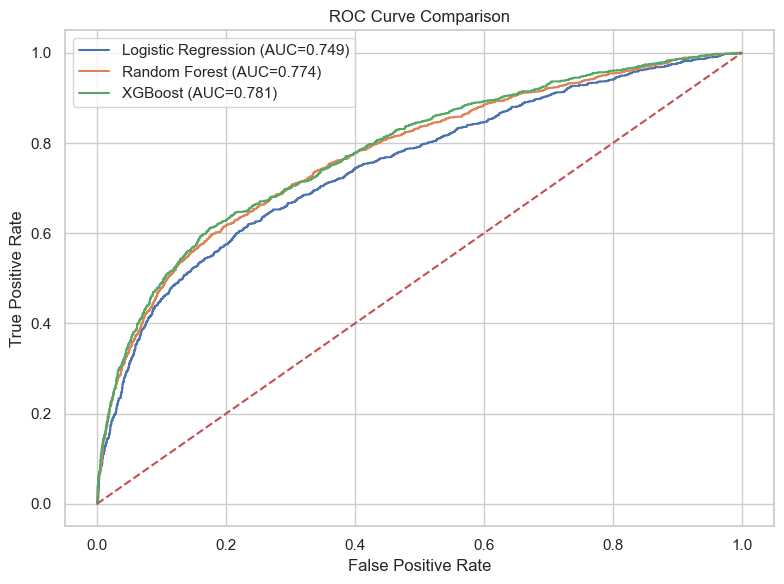

In [4]:
plt.figure(figsize=(8, 6))
for name, probs in probabilities_by_model.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    from sklearn.metrics import roc_auc_score
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "roc_curves.png", dpi=200)
plt.show()

## 4. Confusion matrix for best AUC candidate

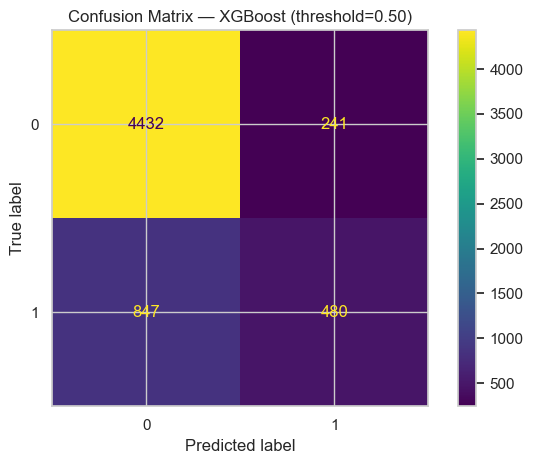

In [5]:
best_name = evaluation["ROC_AUC"].idxmax()
best_probs = probabilities_by_model[best_name]
best_predictions = (best_probs >= 0.50).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions)
plt.title(f"Confusion Matrix — {best_name} (threshold=0.50)")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "best_model_confusion_matrix.png", dpi=200)
plt.show()

## 5. Decile analysis

In [6]:
deciles = decile_table(y_test, best_probs, n_bins=10)
display(deciles)
deciles.to_csv(PROJECT_ROOT / "reports" / "best_model_deciles.csv", index=False)

,decile,customers,average_pd,observed_default_rate,defaults
9,10,600,0.720176,0.693333,416
8,9,600,0.435093,0.438333,263
7,8,600,0.278736,0.271667,163
6,7,600,0.199256,0.166667,100
5,6,600,0.159829,0.181667,109
4,5,600,0.131928,0.153333,92
3,4,600,0.107249,0.098333,59
2,3,600,0.084316,0.095000,57
1,2,600,0.062173,0.066667,40
0,1,600,0.037099,0.046667,28


## 6. Calibration curve

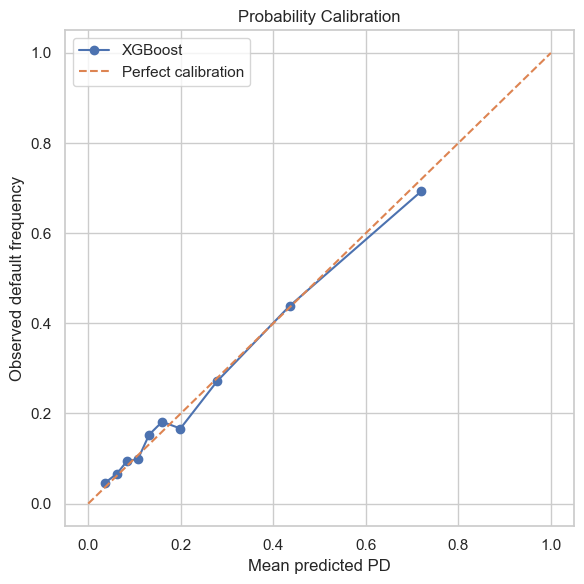

In [7]:
from sklearn.calibration import calibration_curve
fraction_pos, mean_pred = calibration_curve(y_test, best_probs, n_bins=10, strategy="quantile")
plt.figure(figsize=(6, 6))
plt.plot(mean_pred, fraction_pos, marker="o", label=best_name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted PD")
plt.ylabel("Observed default frequency")
plt.title("Probability Calibration")
plt.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "calibration_curve.png", dpi=200)
plt.show()

## 7. Interpretation and limitations

- Gini = 2 × ROC-AUC − 1.
- KS is the maximum separation between cumulative distributions of defaulters and non-defaulters.
- Brier score measures squared probability error; lower is better.
- A 0.50 threshold is a demonstration setting, not a lending decision policy.
- Review false positives and false negatives in the context of approval economics and customer impact.
- A formal independent model validation and out-of-time test are required before real-world use.